In [1]:
print("hello, job market analytics")

hello, job market analytics


In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
print("libraries loaded successfully!")


libraries loaded successfully!


In [3]:
import os 
print(os.listdir("../data"))

[]


In [4]:
import os
print(os.listdir("../data"))

['postings.csv', 'raw_jobs.csv']


In [1]:
df = pd.read_csv("../data/raw_jobs.csv")
df.head()

NameError: name 'pd' is not defined

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/raw_jobs.csv")
df.head()

,job_id,title,company_name,location,description,experience_level,work_type,remote_allowed,min_salary,med_salary,max_salary,pay_period,currency,normalized_salary,views,applies,listed_time,industry_name
0,3902931205,Warehouse,Associated Materials,"Spokane, WA","Warehouse Associate\n\nSince 2022, Associated ...",Entry level,Full-time,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,NaN,1.713279e+12,Wholesale Building Materials
1,3894855473,Influencer Talent Manager - Beauty,Agency Cliquish,"Atlanta, GA",Interested in joining our influencer talent ma...,NaN,Full-time,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,1.0,1.712856e+12,Advertising Services
2,3899525675,Talent Attraction Specialist,LHH,"Greenville, SC",Talent Specialist - Hybrid Role Must be locate...,Entry level,Full-time,NaN,NaN,50000.0,NaN,YEARLY,USD,50000.0,34.0,6.0,1.713279e+12,Staffing and Recruiting
3,3887106339,Retail Sales - Shoes - Stonebriar Centre,Nordstrom,"Frisco, TX",The ideal Salesperson is passionate about fash...,Entry level,Full-time,NaN,15.0,NaN,100.0,HOURLY,USD,119600.0,1.0,NaN,1.712670e+12,Retail
4,3894555810,"Physician Assistant, Per Diem - Internal Medicine",NYU Langone Health,"Mineola, NY",1126363_RR00090444 Job ID: 1126363_RR00090444\...,NaN,Temporary,NaN,NaN,88.0,NaN,HOURLY,USD,183040.0,3.0,NaN,1.712891e+12,Hospitals and Health Care


In [4]:
print(df.shape)
df.info()

(30000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             30000 non-null  int64  
 1   title              30000 non-null  object 
 2   company_name       29593 non-null  object 
 3   location           30000 non-null  object 
 4   description        30000 non-null  object 
 5   experience_level   22955 non-null  object 
 6   work_type          30000 non-null  object 
 7   remote_allowed     3700 non-null   float64
 8   min_salary         7216 non-null   float64
 9   med_salary         1500 non-null   float64
 10  max_salary         7216 non-null   float64
 11  pay_period         8716 non-null   object 
 12  currency           8716 non-null   object 
 13  normalized_salary  8716 non-null   float64
 14  views              29605 non-null  float64
 15  applies            5798 non-null   float64
 16  listed_tim

In [5]:
# Drop columns jo bahut zyada missing hain aur project ke liye critical nahi
df_clean = df.drop(columns=['med_salary', 'applies', 'remote_allowed'])

# Missing text columns ko "Not Specified" / "Unknown" se fill karo
df_clean['experience_level'] = df_clean['experience_level'].fillna('Not Specified')
df_clean['company_name'] = df_clean['company_name'].fillna('Unknown')
df_clean['industry_name'] = df_clean['industry_name'].fillna('Unknown')

# Views me missing ko 0 maan lo (matlab koi record nahi mila)
df_clean['views'] = df_clean['views'].fillna(0)

# Sirf wahi rows rakho jinme koi salary info ho (min/max/normalized)
df_clean = df_clean.dropna(subset=['normalized_salary'], how='all')

print(df_clean.shape)
df_clean.info()

(8716, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 8716 entries, 2 to 29997
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             8716 non-null   int64  
 1   title              8716 non-null   object 
 2   company_name       8716 non-null   object 
 3   location           8716 non-null   object 
 4   description        8716 non-null   object 
 5   experience_level   8716 non-null   object 
 6   work_type          8716 non-null   object 
 7   min_salary         7216 non-null   float64
 8   max_salary         7216 non-null   float64
 9   pay_period         8716 non-null   object 
 10  currency           8716 non-null   object 
 11  normalized_salary  8716 non-null   float64
 12  views              8716 non-null   float64
 13  listed_time        8716 non-null   float64
 14  industry_name      8716 non-null   object 
dtypes: float64(5), int64(1), object(9)
memory usage: 1.1+ MB


In [6]:
# Currency aur pay_period ka spread dekho
print(df_clean['currency'].value_counts())
print()
print(df_clean['pay_period'].value_counts())

currency
USD    8713
EUR       2
CAD       1
Name: count, dtype: int64

pay_period
YEARLY      5021
HOURLY      3538
MONTHLY      117
WEEKLY        38
BIWEEKLY       2
Name: count, dtype: int64


In [7]:
# Location ko city aur state me split karo
df_clean[['city', 'state']] = df_clean['location'].str.split(',', n=1, expand=True)
df_clean['city'] = df_clean['city'].str.strip()
df_clean['state'] = df_clean['state'].str.strip()

df_clean[['location', 'city', 'state']].head()

,location,city,state
2,"Greenville, SC",Greenville,SC
3,"Frisco, TX",Frisco,TX
4,"Mineola, NY",Mineola,NY
5,"Pittsburgh, PA",Pittsburgh,PA
6,"Hot Springs, AR",Hot Springs,AR


In [8]:
# Sirf USD wali rows rakho (CAD wali ek row negligible hai)
df_clean = df_clean[df_clean['currency'] == 'USD']

# Duplicate job_id check karo aur hatao
print("Duplicates:", df_clean['job_id'].duplicated().sum())
df_clean = df_clean.drop_duplicates(subset='job_id')

# Original 'location' column ab zarurat nahi (city/state ban gaya)
df_clean = df_clean.drop(columns=['location'])

print(df_clean.shape)
df_clean.head()

Duplicates: 0
(8713, 16)


,job_id,title,company_name,description,experience_level,work_type,min_salary,max_salary,pay_period,currency,normalized_salary,views,listed_time,industry_name,city,state
2,3899525675,Talent Attraction Specialist,LHH,Talent Specialist - Hybrid Role Must be locate...,Entry level,Full-time,NaN,NaN,YEARLY,USD,50000.0,34.0,1.713279e+12,Staffing and Recruiting,Greenville,SC
3,3887106339,Retail Sales - Shoes - Stonebriar Centre,Nordstrom,The ideal Salesperson is passionate about fash...,Entry level,Full-time,15.00,100.00,HOURLY,USD,119600.0,1.0,1.712670e+12,Retail,Frisco,TX
4,3894555810,"Physician Assistant, Per Diem - Internal Medicine",NYU Langone Health,1126363_RR00090444 Job ID: 1126363_RR00090444\...,Not Specified,Temporary,NaN,NaN,HOURLY,USD,183040.0,3.0,1.712891e+12,Hospitals and Health Care,Mineola,NY
5,3905356677,Application Development - Permit Coordinator IV,Randstad Digital Americas,Job Summary\n\nThis position is responsible fo...,Not Specified,Contract,30.53,38.53,HOURLY,USD,71822.4,4.0,1.713490e+12,IT Services and IT Consulting,Pittsburgh,PA
6,3904960516,Multimedia Journalist,The Sentinel-Record,Calling All News Ninjas! The Sentinel-Record W...,Not Specified,Full-time,NaN,NaN,HOURLY,USD,31200.0,10.0,1.713457e+12,Newspaper Publishing,Hot Springs,AR


In [9]:
df_clean.to_csv("../data/cleaned_jobs.csv", index=False)
print("Saved cleaned_jobs.csv ✅")

Saved cleaned_jobs.csv ✅


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("../data/cleaned_jobs.csv")
df.head()

,job_id,title,company_name,description,experience_level,work_type,min_salary,max_salary,pay_period,currency,normalized_salary,views,listed_time,industry_name,city,state
0,3899525675,Talent Attraction Specialist,LHH,Talent Specialist - Hybrid Role Must be locate...,Entry level,Full-time,NaN,NaN,YEARLY,USD,50000.0,34.0,1.713279e+12,Staffing and Recruiting,Greenville,SC
1,3887106339,Retail Sales - Shoes - Stonebriar Centre,Nordstrom,The ideal Salesperson is passionate about fash...,Entry level,Full-time,15.00,100.00,HOURLY,USD,119600.0,1.0,1.712670e+12,Retail,Frisco,TX
2,3894555810,"Physician Assistant, Per Diem - Internal Medicine",NYU Langone Health,1126363_RR00090444 Job ID: 1126363_RR00090444\...,Not Specified,Temporary,NaN,NaN,HOURLY,USD,183040.0,3.0,1.712891e+12,Hospitals and Health Care,Mineola,NY
3,3905356677,Application Development - Permit Coordinator IV,Randstad Digital Americas,Job Summary\n\nThis position is responsible fo...,Not Specified,Contract,30.53,38.53,HOURLY,USD,71822.4,4.0,1.713490e+12,IT Services and IT Consulting,Pittsburgh,PA
4,3904960516,Multimedia Journalist,The Sentinel-Record,Calling All News Ninjas! The Sentinel-Record W...,Not Specified,Full-time,NaN,NaN,HOURLY,USD,31200.0,10.0,1.713457e+12,Newspaper Publishing,Hot Springs,AR


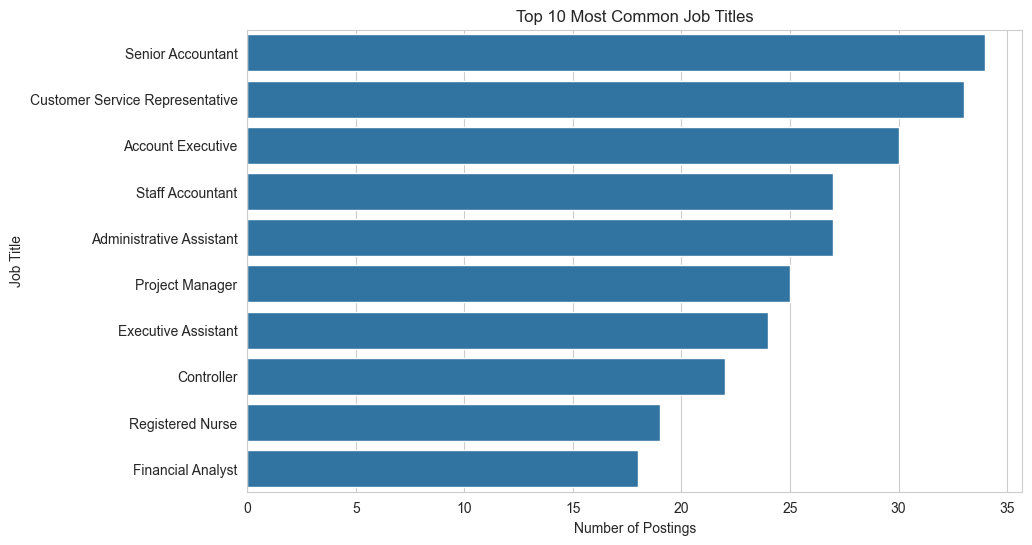

In [11]:
top_titles = df['title'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_titles.values, y=top_titles.index)
plt.title("Top 10 Most Common Job Titles")
plt.xlabel("Number of Postings")
plt.ylabel("Job Title")
plt.show()

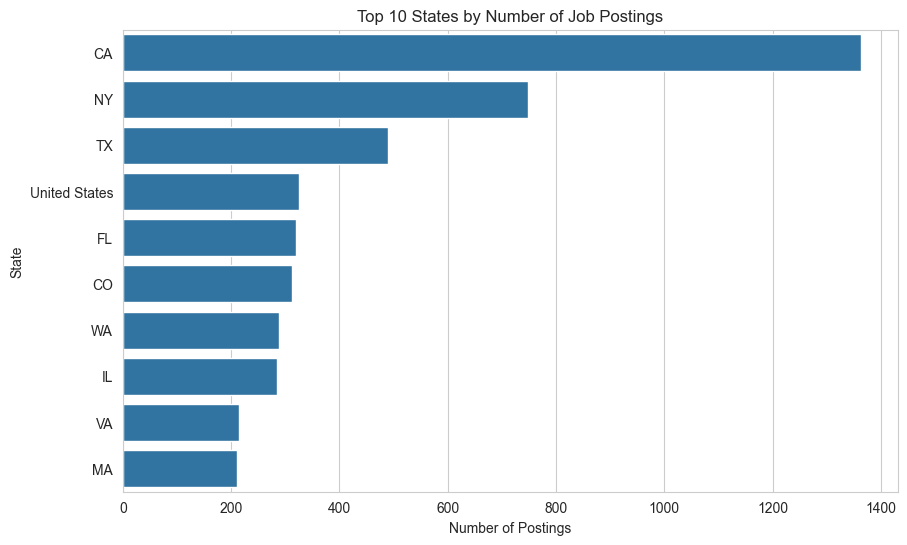

In [12]:
top_locations = df['state'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_locations.values, y=top_locations.index)
plt.title("Top 10 States by Number of Job Postings")
plt.xlabel("Number of Postings")
plt.ylabel("State")
plt.show()

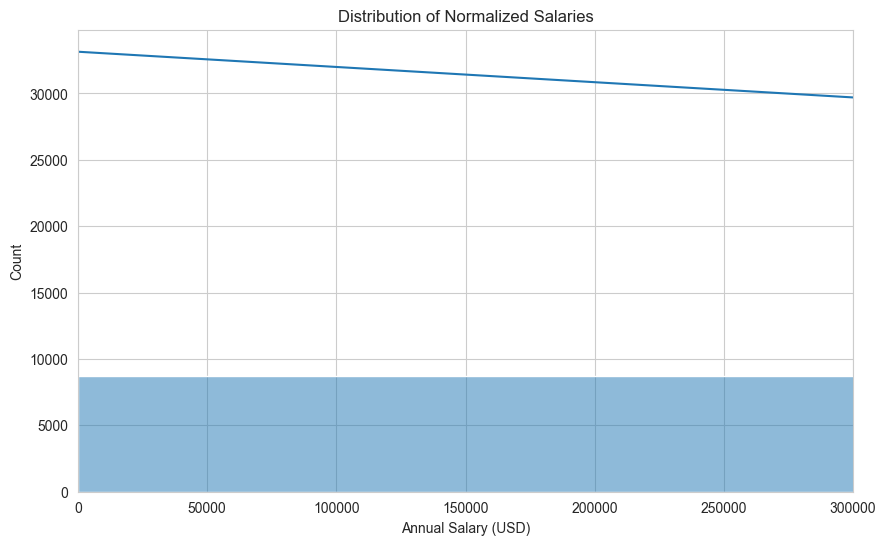

In [13]:
plt.figure(figsize=(10,6))
sns.histplot(df['normalized_salary'], bins=50, kde=True)
plt.title("Distribution of Normalized Salaries")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Count")
plt.xlim(0, 300000)  # extreme outliers hata ke dikhane ke liye
plt.show()

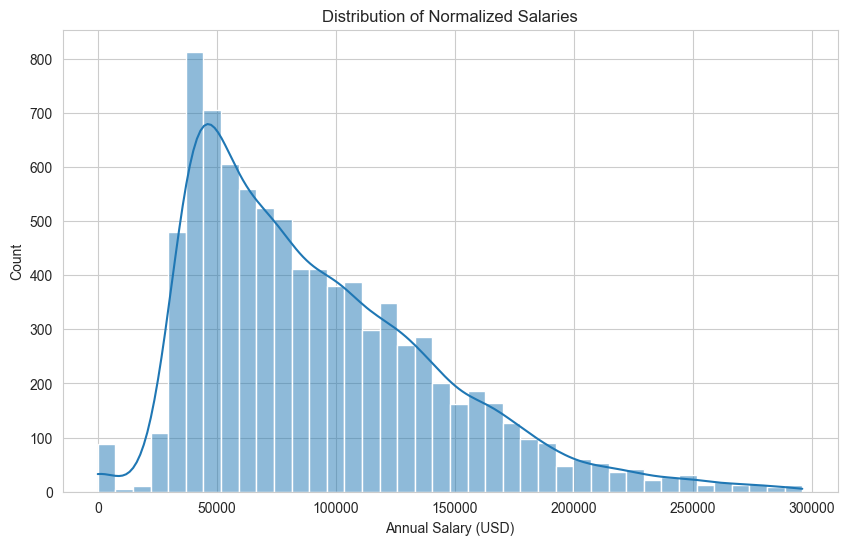

In [14]:
plt.figure(figsize=(10,6))

# Pehle hi extreme outliers hatao, phir plot karo
salary_data = df[(df['normalized_salary'] > 0) & (df['normalized_salary'] < 300000)]['normalized_salary']

sns.histplot(salary_data, bins=40, kde=True)
plt.title("Distribution of Normalized Salaries")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Count")
plt.show()

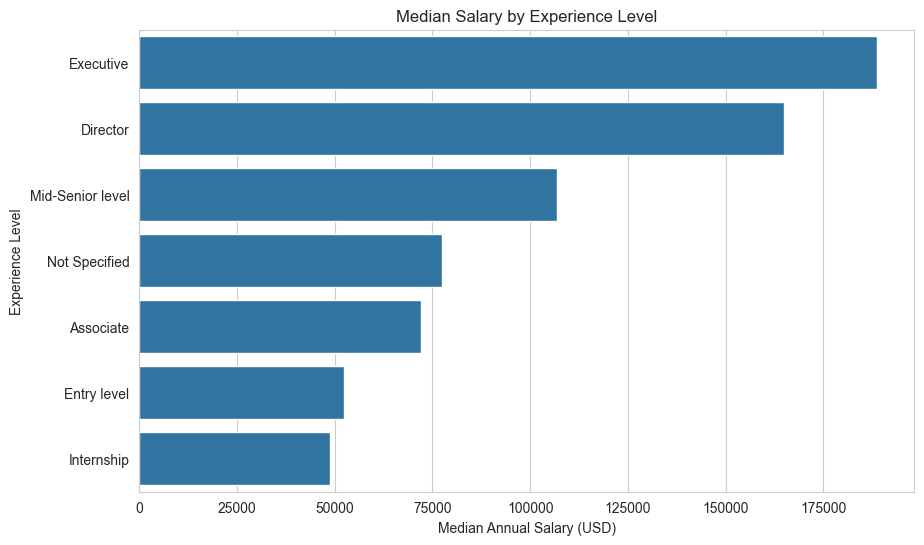

In [15]:
plt.figure(figsize=(10,6))
exp_salary = df.groupby('experience_level')['normalized_salary'].median().sort_values(ascending=False)
sns.barplot(x=exp_salary.values, y=exp_salary.index)
plt.title("Median Salary by Experience Level")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Experience Level")
plt.show()

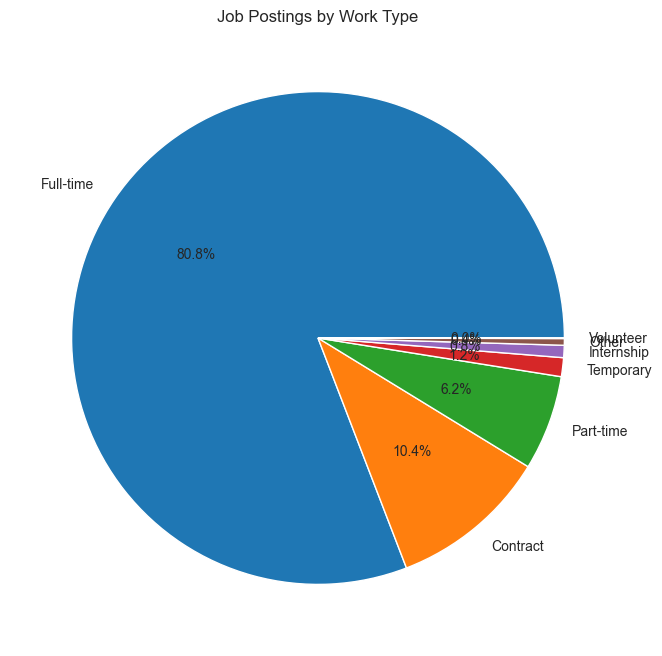

In [16]:
plt.figure(figsize=(8,8))
df['work_type'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Job Postings by Work Type")
plt.ylabel("")
plt.show()